# Итоговое сравнение моделей классификации и регрессии

**Цель исследования** — сравнить пять семейств алгоритмов на одинаковых тестовых выборках, оценить эффект подбора гиперпараметров и сопоставить библиотечные и собственные реализации.

## Данные и метрики

- **Wall-Following Robot Navigation Data.** 5 456 наблюдений, 24 показания ультразвуковых датчиков, цель — один из четырёх манёвров робота. Обучение на первых 4 274 строках, затем зазор 90 строк и тест на последних 1 092 строках. [Источник UCI](https://archive.ics.uci.edu/dataset/194/wall+following+robot+navigation+data)
- **CPU Activity.** 8 192 наблюдения, 21 системный счётчик, цель — доля времени работы CPU в пользовательском режиме (`usr`, %). Первые 6 553 строки использовались для обучения, последние 1 639 — для теста. [Источник OpenML](https://www.openml.org/d/44132)

Во всех работах сохранялся порядок строк. Подбор проводился на обучающих данных с тремя последовательными фолдами `TimeSeriesSplit` и зазором 90 строк для робота. Тестовые блоки использовались для итоговой оценки.

Для классификации выше — лучше по обеим метрикам. Accuracy — доля правильных ответов, F1-macro — среднее F1 по классам с равным весом каждого класса. Для регрессии меньшее значение предпочтительно по MAE и RMSE, выраженным в процентных пунктах, а большее — по коэффициенту детерминации R². RMSE сильнее учитывает большие ошибки.

## Тестовые результаты

Прочитаем сохранённые HTML-таблицы из итоговых ячеек пяти лабораторных. В работах № 1 и 2 таблицы содержат только тестовые метрики, в работах № 3–5 возьмём строки «Тест». Сравнение ведём с точностью сохранённых значений — четыре знака после запятой.

In [1]:
from pathlib import Path
from xml.etree import ElementTree

import matplotlib.pyplot as plt
import nbformat
import pandas as pd
from IPython.display import display

sources = [
    ("lab1_knn.ipynb", 31, "KNN", "KNN"),
    ("lab2_regression.ipynb", 21, "Логистическая регрессия", "Линейная регрессия"),
    ("lab3_decision_tree.ipynb", 23, "Решающее дерево", "Решающее дерево"),
    ("lab4_random_forest.ipynb", 29, "Случайный лес", "Случайный лес"),
    ("lab5_gradient_boosting.ipynb", 31, "Градиентный бустинг", "Градиентный бустинг"),
]
variants = ["Исходная sklearn", "Улучшенная sklearn", "Собственная", "Улучшенная собственная"]
model_labels = {
    "Исходный sklearn": variants[0], "Исходная sklearn": variants[0],
    "Улучшенный sklearn": variants[1], "Улучшенная sklearn": variants[1],
    "Собственная реализация": variants[2], "Собственная": variants[2],
    "Улучшенная собственная реализация": variants[3], "Улучшенная собственная": variants[3],
}
classification_metrics = ["Accuracy", "F1-macro"]
regression_metrics = ["MAE, п. п.", "RMSE, п. п.", "R²"]


def read_scores(tables, metrics, source):
    matches = [table for table in tables if set(metrics).issubset(
        cell.text for cell in table.findall("thead/tr[1]/th")
    )]
    if len(matches) != 1:
        raise ValueError(f"{source} — ожидалась одна сохранённая таблица с метриками {metrics}.")
    table = matches[0]
    headers = [cell.text for cell in table.findall("thead/tr[1]/th") if cell.text]
    scores = {}
    for row in table.findall("tbody/tr"):
        labels = [cell.text for cell in row.findall("th")]
        if labels[0] in model_labels:
            variant = model_labels[labels[0]]
        if labels[-1] == "Обучение":
            continue
        values = dict(zip(headers, (cell.text for cell in row.findall("td"))))
        if variant in scores:
            raise ValueError(f"{source} — повтор строки {variant}.")
        scores[variant] = {metric: float(values[metric]) for metric in metrics}
    if set(scores) != set(variants):
        raise ValueError(f"{source} — отсутствуют результаты {set(variants) - set(scores)}.")
    return pd.DataFrame.from_dict(scores, orient="index").loc[variants]


classification = {}
regression = {}
for filename, cell_index, classifier, regressor in sources:
    notebook = nbformat.read(Path(filename), as_version=4)
    tables = []
    for output in notebook.cells[cell_index].get("outputs", []):
        html = output.get("data", {}).get("text/html", "")
        if "<table" in html:
            fragment = html[html.index("<table"):html.index("</table>") + len("</table>")]
            tables.append(ElementTree.fromstring(fragment))
    classification[classifier] = read_scores(tables, classification_metrics, filename)
    regression[regressor] = read_scores(tables, regression_metrics, filename)

classification = pd.concat(classification, names=["Алгоритм", "Вариант"])
regression = pd.concat(regression, names=["Алгоритм", "Вариант"])
display(classification.style.format("{:.4f}"))
display(regression.style.format("{:.4f}"))


## Сравнение по метрикам

Построим отдельный график для каждой метрики. В каждой группе четыре столбца с одинаковым порядком и цветом вариантов. Точные сохранённые значения подписаны у столбцов.

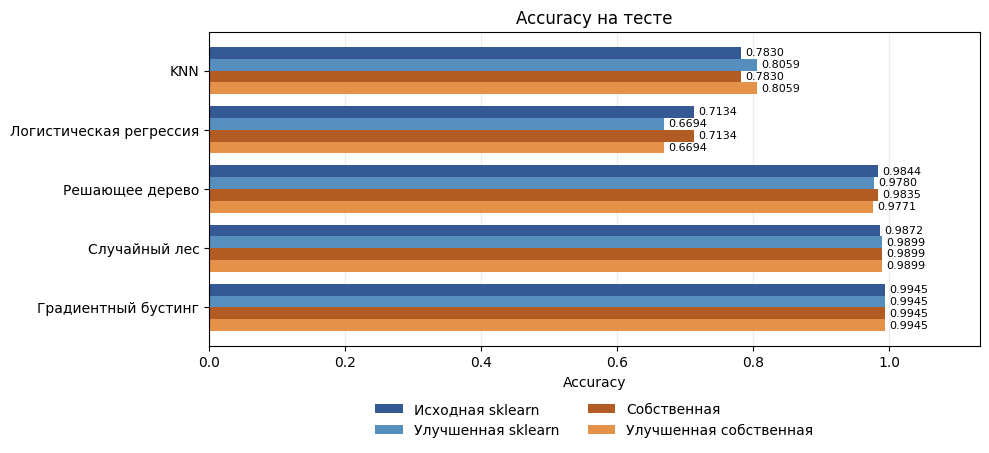

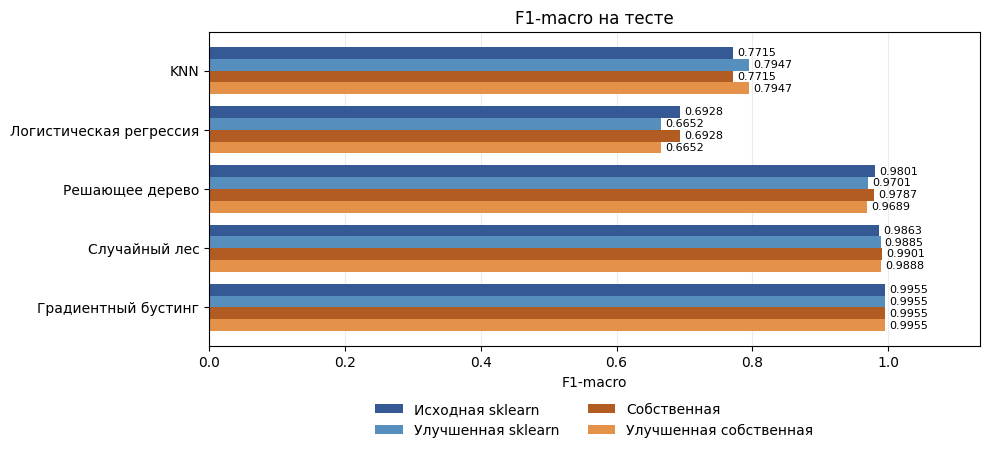

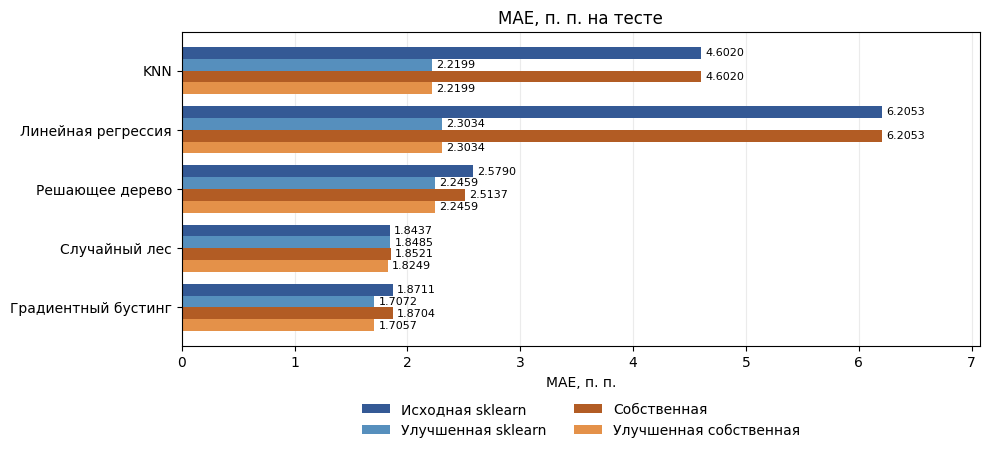

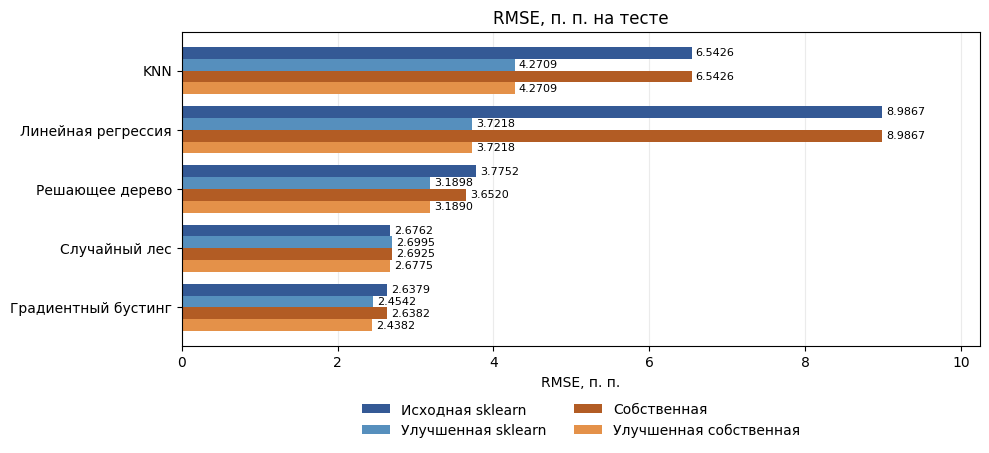

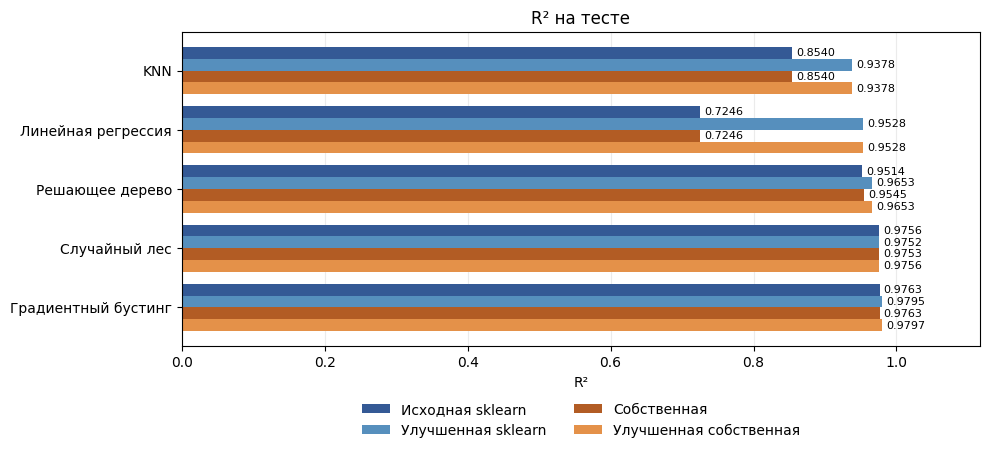

In [2]:
colors = ["#345995", "#568FBD", "#B25C24", "#E49149"]
for results in (classification, regression):
    for metric in results:
        values = results[metric].unstack("Вариант")
        algorithms = results.index.get_level_values("Алгоритм").unique()
        values = values.loc[algorithms, variants]
        ax = values.plot.barh(figsize=(10, 4.7), color=colors, width=0.8)
        ax.invert_yaxis()
        ax.set(xlabel=metric, ylabel="", title=f"{metric} на тесте")
        ax.set_xlim(0, values.max().max() * 1.14)
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)
        for bars in ax.containers:
            ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncols=2, frameon=False)
        fig = ax.figure
        fig.tight_layout()
        plt.show()
        plt.close(fig)


## Лучшие модели

Найдём максимум Accuracy, F1-macro и R² и минимум MAE и RMSE. При равенстве сохранённых значений покажем все варианты с этим результатом.

In [3]:
leaders = []
for results in (classification, regression):
    for metric, values in results.items():
        minimize = metric in ["MAE, п. п.", "RMSE, п. п."]
        best = values.min() if minimize else values.max()
        for algorithm, variant in values[values == best].index:
            leaders.append({
                "Метрика": metric, "Направление": "Минимум" if minimize else "Максимум",
                "Алгоритм": algorithm, "Вариант": variant, "Значение": f"{best:.4f}",
            })
display(pd.DataFrame(leaders).set_index("Метрика"))


,Направление,Алгоритм,Вариант,Значение
Метрика,,,,
Accuracy,Максимум,Градиентный бустинг,Исходная sklearn,0.9945
Accuracy,Максимум,Градиентный бустинг,Улучшенная sklearn,0.9945
Accuracy,Максимум,Градиентный бустинг,Собственная,0.9945
Accuracy,Максимум,Градиентный бустинг,Улучшенная собственная,0.9945
F1-macro,Максимум,Градиентный бустинг,Исходная sklearn,0.9955
F1-macro,Максимум,Градиентный бустинг,Улучшенная sklearn,0.9955
F1-macro,Максимум,Градиентный бустинг,Собственная,0.9955
F1-macro,Максимум,Градиентный бустинг,Улучшенная собственная,0.9955
"MAE, п. п.",Минимум,Градиентный бустинг,Улучшенная собственная,1.7057


## Сравнение исходных и улучшенных моделей

- **KNN.** Подбор улучшил все тестовые метрики в обеих реализациях. F1-macro вырос с 0,7715 до 0,7947, MAE снизилась с 4,6020 до 2,2199 п. п.
- **Логистическая и линейная регрессии.** У классификатора обе тестовые метрики ухудшились, F1-macro снизился с 0,6928 до 0,6652. У регрессора улучшились все метрики, в том числе MAE с 6,2053 до 2,3034 п. п. Результаты одинаковы у sklearn и собственной реализации в сохранённой точности.
- **Решающее дерево.** После подбора Accuracy и F1-macro снизились у обоих классификаторов. В регрессии улучшились все метрики обеих реализаций, а MAE каждой улучшенной модели составила 2,2459 п. п.
- **Случайный лес.** У классификатора sklearn F1-macro вырос с 0,9863 до 0,9885. У собственного классификатора он снизился с 0,9901 до 0,9888 при той же Accuracy 0,9899. В регрессии все три метрики sklearn ухудшились, в том числе MAE с 1,8437 до 1,8485 п. п. У собственной модели все три метрики улучшились, MAE снизилась с 1,8521 до 1,8249 п. п.
- **Градиентный бустинг.** У обеих реализаций классификатора Accuracy и F1-macro сохранились до четырёх знаков. У обеих реализаций регрессора улучшились все метрики.

## Сравнение sklearn и собственных реализаций

У KNN, логистической и линейной регрессий все парные оценки совпали до четырёх знаков. У решающего дерева sklearn чуть выше обе метрики классификации, а собственное дерево даёт меньшую RMSE в обеих конфигурациях регрессии. У случайного леса собственный классификатор имеет более высокий F1-macro при обеих конфигурациях. В регрессии исходный лес sklearn лучше собственной исходной модели по всем трём метрикам, а после подбора соотношение меняется. В градиентном бустинге классификационные метрики совпали. В регрессии улучшенная собственная модель немного опережает улучшенную sklearn по всем трём метрикам.

## Общий вывод

Градиентный бустинг лидирует на обоих тестовых наборах. В классификации первое место делят все четыре его варианта с Accuracy 0,9945 и F1-macro 0,9955. В регрессии лучшие MAE 1,7057 п. п., RMSE 2,4382 п. п. и R² 0,9797 у улучшенного собственного бустинга. Подбор помог всем семействам регрессоров хотя бы в одной реализации, но у библиотечного случайного леса качество ухудшилось. Для классификации эффект подбора зависел от алгоритма и реализации. Эти выводы относятся к сохранённым тестовым блокам и точности опубликованных оценок.